# Population, mobilités et accès au rail

Ce notebook utilise la base communale finale pour regarder où la population augmente, comment les actifs se déplacent et comment ces tendances se rapprochent de l'accès au rail.

Les voyageurs sont disponibles pour 2017 et 2023, regroupés par commune. On ne peut donc pas suivre chaque gare ni mesurer ici la reprise après la pandémie. Les données nécessaires aux calculs avion et CO₂ ne sont pas dans cette base.

## 0. Données et contrôles

Lecture de la base, contrôle des colonnes et des valeurs manquantes (facultatif). Les colonnes de géométrie (c'est non numériques et n'a aucune incidence sur les statistiques descriptives) sont conservées dans la base, mais exclues des tableaux.

In [1]:
from pathlib import Path
import sys
import math
import numpy as np
import pandas as pd
from IPython.display import display

# Trouver la racine du projet, que le notebook soit ouvert depuis notebooks/ ou la racine.
DOSSIER_COURANT = Path.cwd().resolve()
RACINES = [DOSSIER_COURANT, *DOSSIER_COURANT.parents]
RACINE_PROJET = next(
    (racine for racine in RACINES if (racine / "src" / "analyse_mobilites.py").exists()),
    DOSSIER_COURANT,
)
if str(RACINE_PROJET) not in sys.path:
    sys.path.insert(0, str(RACINE_PROJET))

# Les fonctions réutilisables sont gardées dans src, pas recopiées dans le notebook.
from src.analyse_mobilites import (
    arrondir_tableau,
    calculer_acp,
    indice_gini,
    indice_hoover,
    indice_theil,
    intensite_ternaire,
    resume_par_strate,
    resume_part_voiture,
    synthese_croissance_par,
    tracer_acp,
)

# Charger la base du dépôt ou, à défaut, le parquet placé à côté du notebook.
CANDIDATS_PARQUET = [
    RACINE_PROJET / "data" / "clean" / "base_finale" / "base_finale_communes_variables.parquet",
    RACINE_PROJET / "communes.parquet",
    DOSSIER_COURANT / "communes.parquet",
]
FICHIER = next((chemin for chemin in CANDIDATS_PARQUET if chemin.exists()), CANDIDATS_PARQUET[0])
if not FICHIER.exists():
    raise FileNotFoundError(f"Base communale introuvable. Chemins vérifiés : {CANDIDATS_PARQUET}")

communes = pd.read_parquet(FICHIER)
print(f"Base : {FICHIER.name}")
print(f"{len(communes):,} communes, {len(communes.columns)} variables")
display(arrondir_tableau(communes.head(5), decimales=2))

description_colonnes = pd.DataFrame({
    "type": communes.dtypes.astype(str),
    "valeurs non manquantes": communes.notna().sum(),
    "valeurs manquantes": communes.isna().sum(),
    "part manquante (%)": (100 * communes.isna().mean()).round(2),
})
display(arrondir_tableau(description_colonnes, decimales=2))


Base : base_finale_communes_variables.parquet
34,746 communes, 48 variables


,code_commune,nom_commune,code_departement,code_region,geometry,pop_2017,statut_pop_2017,alerte_population_2017,pop_2023,statut_pop_2023,...,tcam_voyageurs_2017_2023,voyageurs_hab_2023,part_voiture_2017,part_voiture_2023,part_voiture_toutes_2023,voitures_1000_hab_2023,densite,classe_taille,profil,desservie
0,75056,Paris,75,11,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00e\x00\x0...,2187526,A,False,2103778,A,...,-1.35,360.19,11.20,8.98,8.98,189.29,"19,960",50 000 et plus,déclin ou stable – desservie,True
1,77072,Chalautre-la-Grande,77,11,b'\x01\x03\x00\x00\x00\x01\x00\x00\x004\x00\x0...,703,A,False,644,A,...,NaN,NaN,NaN,NaN,79.44,602.48,35.13,500 à 2 000,déclin ou stable – desservie,True
2,77187,Fontaine-Fourches,77,11,"b'\x01\x03\x00\x00\x00\x01\x00\x00\x00,\x00\x0...",602,A,False,576,A,...,NaN,NaN,NaN,NaN,86.51,680.56,48.65,500 à 2 000,déclin ou stable – non desservie,False
3,77522,Villiers-sur-Seine,77,11,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00+\x00\x0...,300,A,False,278,A,...,NaN,NaN,NaN,NaN,82.59,636.69,24.45,moins de 500,déclin ou stable – desservie,True
4,77523,Villuis,77,11,"b'\x01\x03\x00\x00\x00\x01\x00\x00\x00""\x00\x0...",265,A,False,272,A,...,NaN,NaN,NaN,NaN,79.23,632.35,29.37,moins de 500,croissance – non desservie,False


,type,valeurs non manquantes,valeurs manquantes,part manquante (%)
code_commune,str,34746,0,0
nom_commune,str,34746,0,0
code_departement,str,34746,0,0
code_region,str,34746,0,0
geometry,object,34746,0,0
pop_2017,float64,34746,0,0
statut_pop_2017,string,34746,0,0
alerte_population_2017,bool[pyarrow],34746,0,0
pop_2023,float64,34746,0,0
statut_pop_2023,string,34746,0,0


### Un petit bilan sur la base

On peut toutefois décrire les rattachements visibles dans la base finale : communes avec gare, voyageurs renseignés et population correspondante. Ce contrôle n'est pas un taux de couverture des voyageurs de la source initiale, car son total avant jointure n'est pas présent ici.

In [2]:
# ==================================================================
# 2. PREMIÈRE DESCRIPTION DE LA BASE
# ==================================================================
# Objectif : isoler les variables numériques et compter les observations disponibles.
# Les valeurs manquantes sont conservées : elles ne sont pas imputées ici.

# Étape 1 — exclure les identifiants textuels et la géométrie des tableaux numériques.
variables_numeriques = communes.select_dtypes(include='number').columns
synthese_variables = communes[variables_numeriques].describe(
    percentiles=[0.25, 0.50, 0.75]
).T.rename(columns={
    'mean': 'moyenne', 'std': 'écart-type', 'min': 'minimum',
    '25%': 'Q1', '50%': 'médiane', '75%': 'Q3', 'max': 'maximum',
})[['moyenne', 'médiane', 'écart-type', 'minimum', 'maximum', 'Q1', 'Q3']]
display(arrondir_tableau(synthese_variables))

# Le nombre de gares permet de calculer la desserte visible, mais pas la catégorie A/B/C.
# Étape 2 — définir les exclusions visibles uniquement à partir des variables présentes.
communes_avec_gare = communes['nb_gares'].gt(0)
voyageurs_renseignes_2023 = communes['voyageurs_2023'].notna()
bilan_visible = pd.DataFrame({
    'indicateur': [
        'Communes ayant au moins une gare',
        'Communes avec voyageurs renseignés en 2017',
        'Communes avec voyageurs renseignés en 2023',
        'Population 2023 dans les communes avec voyageurs renseignés',
        'Communes sans gare (aucune correspondance visible dans le parquet)',
        'Communes sous le seuil de 1 000 actifs en 2017 ou actifs manquants',
        'Gares à zéro voyageur en 2017 (communes desservies)',
        'Gares à zéro voyageur en 2023 (communes desservies)',
    ],
    'valeur': [
        int(communes_avec_gare.sum()),
        int(communes['voyageurs_2017'].notna().sum()),
        int(voyageurs_renseignes_2023.sum()),
        int(communes.loc[voyageurs_renseignes_2023, 'pop_2023'].sum()),
        int((~communes_avec_gare).sum()),
        int((communes['actifs_2017'].isna() | communes['actifs_2017'].lt(1000)).sum()),
        int((communes_avec_gare & communes['voyageurs_2017'].eq(0)).sum()),
        int((communes_avec_gare & communes['voyageurs_2023'].eq(0)).sum()),
    ],
})
display(bilan_visible)
print('La part des voyageurs couverte par la jointure initiale et le bilan A/B/C ne figurent pas dans cette base.')

# Le chiffre publié par l'INSEE n'est pas une variable de la base mais on considére celle recalculée
population_insee_publiee_2023 = None
population_recalculee = communes['pop_2023'].sum()
print(f'Population 2017 recalculée : {communes["pop_2017"].sum():,.0f}')
print(f'Population 2023 recalculée : {population_recalculee:,.0f}')
if population_insee_publiee_2023 is None:
    print('Comparaison INSEE non chiffrée : la référence publiée doit être fournie pour éviter une valeur non vérifiée.')
else:
    print(f'Écart au chiffre INSEE fourni : {population_recalculee - population_insee_publiee_2023:,.0f} habitants')
print('La variable statut_pop indique la qualité des populations communales ; elle ne décrit pas une catégorie de gare.')

,moyenne,médiane,écart-type,minimum,maximum,Q1,Q3
pop_2017,"1,860.33",456,"15,053.44",0,"2,187,526",198,"1,147"
pop_2023,"1,904.27",456,"14,909.33",0,"2,103,778",197,"1,163"
superficie_km2,15.65,10.92,17.06,0.04,758.93,6.48,18.88
naissances_2017_2022,122.01,24,"1,140.57",0,"157,911",9,63
deces_2017_2022,107.47,22,682.30,0,"87,652",10,61
actifs_2017,755.89,193.33,"6,867.40",0,"1,079,584",82.31,485.83
actifs_sans_deplacement_2017,32.29,11.98,299.58,0,"51,413",5.13,26.77
actifs_marche_2017,46.30,5,702.11,0,"109,369",2,14.96
actifs_deux_roues_2017,30.16,2.96,623.54,0,"99,994",0.99,8.68
actifs_voiture_2017,531.11,167,"2,068.75",0,"161,806",69.41,417.50


,indicateur,valeur
0,Communes ayant au moins une gare,2449
1,Communes avec voyageurs renseignés en 2017,2449
2,Communes avec voyageurs renseignés en 2023,2449
3,Population 2023 dans les communes avec voyageu...,30934964
4,Communes sans gare (aucune correspondance visi...,32297
5,Communes sous le seuil de 1 000 actifs en 2017...,30394
6,Gares à zéro voyageur en 2017 (communes desser...,14
7,Gares à zéro voyageur en 2023 (communes desser...,0


La part des voyageurs couverte par la jointure initiale et le bilan A/B/C ne figurent pas dans cette base.
Population 2017 recalculée : 64,639,133
Population 2023 recalculée : 66,165,815
Comparaison INSEE non chiffrée : la référence publiée doit être fournie pour éviter une valeur non vérifiée.
La variable statut_pop indique la qualité des populations communales ; elle ne décrit pas une catégorie de gare.


## 1. Où va la population ?

La croissance annuelle moyenne est un taux composé entre 2017 et 2023 (six ans). Les groupes démographiques sont définis par ce taux : déclin sous −0,2 %/an, stabilité entre −0,2 % et +0,2 % inclus, croissance au-dessus de +0,2 %/an.

In [3]:
# ==================================================================
# 3. CONSTRUCTION DES INDICATEURS DÉMOGRAPHIQUES
# ==================================================================
# Objectif : mesurer l'évolution absolue et le taux composé sur six ans.
# Un taux composé évite de supposer plusieurs croissances additives.

d = communes.copy()
# Étape 1 — créer les variations absolues en habitants.
d['variation_population'] = d['pop_2023'] - d['pop_2017']
# Étape 2 — transformer l'écart 2017–2023 en taux annuel composé.
d['croissance_pop_an_%'] = np.where(
    d['pop_2017'].gt(0) & d['pop_2023'].ge(0),
    ((d['pop_2023'] / d['pop_2017']) ** (1 / 6) - 1) * 100,
    np.nan,
)
# Étape 3 — classer chaque commune selon trois seuils explicités.
d['trajectoire_population'] = pd.cut(
    d['croissance_pop_an_%'],
    bins=[-np.inf, -0.2, 0.2, np.inf],
    labels=['Déclin', 'Stable (±0,2 %/an)', 'Croissance'],
    right=True,
).astype('object')

population_totaux = pd.DataFrame([
    {'année': '2017', 'population': d['pop_2017'].sum()},
    {'année': '2023', 'population': d['pop_2023'].sum()},
    {'année': 'Croissance agrégée (%)',
     'population': 100 * (d['pop_2023'].sum() / d['pop_2017'].sum() - 1)},
])
display(arrondir_tableau(population_totaux))

distribution_croissance = d['croissance_pop_an_%'].describe(percentiles=[0.05, 0.25, 0.75, 0.95])
display(arrondir_tableau(distribution_croissance.rename({
    'mean': 'moyenne', 'std': 'écart-type', 'min': 'minimum', '5%': 'P5',
    '25%': 'P25', '50%': 'médiane', '75%': 'P75', '95%': 'P95', 'max': 'maximum',
}).to_frame('croissance annuelle moyenne (%)')))

# Étape 4 — agréger le nombre de communes, la population et le gain ou la perte.
groupes_population = d.groupby('trajectoire_population', observed=False).agg(
    communes=('code_commune', 'size'),
    part_communes_pct=('code_commune', lambda s: 100 * len(s) / len(d)),
    population_2017=('pop_2017', 'sum'),
    population_2023=('pop_2023', 'sum'),
    variation_population=('variation_population', 'sum'),
).round(2)
display(groupes_population)

,année,population
0,2017,"64,639,133"
1,2023,"66,165,815"
2,Croissance agrégée (%),2.36


,croissance annuelle moyenne (%)
count,"34,740"
moyenne,0.08
écart-type,1.47
minimum,-12.43
P5,-2.10
P25,-0.72
P75,0.83
P95,2.37
maximum,18.36


,communes,part_communes_pct,population_2017,population_2023,variation_population
trajectoire_population,,,,,
Croissance,15447,44.46,36613533.0,38874675.0,2261142.0
Déclin,14405,41.46,17576508.0,16833691.0,-742817.0
"Stable (±0,2 %/an)",4888,14.07,10449092.0,10457449.0,8357.0


### Lecture des résultats démographiques

- La population recalculée passe de **64,64 millions** d'habitants en 2017 à **66,17 millions** en 2023, soit une hausse agrégée de **+2,36 %** sur six ans.
- **44,46 %** des communes sont en croissance, contre **41,46 %** en déclin. Cela masque une forte concentration du gain démographique : près des deux tiers de la population 2023 des communes en croissance sont donc dans les classes dynamisées, sans que l'on puisse déduire une cause directe.
- La croissance médiane annuelle est proche de zéro au niveau communal. Les dynamiques positives et négatives restent donc très déséquilibrées entre communes.

In [4]:
# ==================================================================
# 4. COMPARAISON RÉGIONALE ET PAR CLASSE
# ==================================================================
# Objectif : agréger les communes par région, taille et densité.
# Les seuils sont fixes afin que les tableaux soient reproductibles.

# Étape 1 — convertir les codes régionaux en libellés lisibles.
noms_regions = {
    '11': 'Île-de-France', '24': 'Centre-Val de Loire', '27': 'Bourgogne-Franche-Comté',
    '28': 'Normandie', '32': 'Hauts-de-France', '44': 'Grand Est',
    '52': 'Pays de la Loire', '53': 'Bretagne', '75': 'Nouvelle-Aquitaine',
    '76': 'Occitanie', '84': 'Auvergne-Rhône-Alpes',
    '93': 'Provence-Alpes-Côte d’Azur', '94': 'Corse',
}
d['region'] = d['code_region'].astype(str).map(noms_regions).fillna(d['code_region'].astype(str))
regions = d.groupby('region').agg(
    population_2017=('pop_2017', 'sum'),
    population_2023=('pop_2023', 'sum'),
    naissances_2017_2022=('naissances_2017_2022', 'sum'),
    deces_2017_2022=('deces_2017_2022', 'sum'),
).reset_index()
regions['variation_population'] = regions['population_2023'] - regions['population_2017']
regions['solde_naturel_2017_2022'] = regions['naissances_2017_2022'] - regions['deces_2017_2022']
# Étape 2 — obtenir un résidu apparent entre la variation totale et le solde naturel.
regions['solde_migratoire_apparent'] = regions['variation_population'] - regions['solde_naturel_2017_2022']
regions['croissance_population_%'] = 100 * regions['variation_population'] / regions['population_2017']
display(regions.sort_values('croissance_population_%', ascending=False).round(1))
print('Le solde migratoire apparent est le résidu entre variation 2017–2023 et solde naturel fourni pour 2017–2022 ; les périodes ne coïncident pas exactement.')

# Classes lisibles et stables : taille selon la population 2023, densité selon population/superficie.
# Étape 3 — construire des strates de taille fixes et reproductibles.
d['classe_taille'] = pd.cut(
    d['pop_2023'], bins=[0, 2000, 10000, 50000, np.inf],
    labels=['Moins de 2 000', '2 000–9 999', '10 000–49 999', '50 000 et plus'],
    right=False,
)
d['densite_2023'] = d['pop_2023'] / d['superficie_km2'].replace(0, np.nan)
# Étape 4 — calculer la densité avant de créer les classes.
d['classe_densite'] = pd.cut(
    d['densite_2023'], bins=[-np.inf, 30, 100, 300, np.inf],
    labels=['Moins de 30', '30–99', '100–299', '300 et plus'], right=False,
)

print('Croissance selon la taille de commune (classes établies sur 2023)')
display(synthese_croissance_par(d.groupby('classe_taille', observed=False)))
print('Croissance selon la densité de population 2023 (habitant/km²)')
display(synthese_croissance_par(d.groupby('classe_densite', observed=False)))

grandes_communes = d[d['pop_2023'].gt(10000)]
colonnes_top = ['code_commune', 'nom_commune', 'region', 'pop_2017', 'pop_2023', 'variation_population']
print('5 communes de plus de 10 000 habitants qui gagnent le plus d’habitants')
display(arrondir_tableau(grandes_communes.nlargest(5, 'variation_population')[colonnes_top]))
print('5 communes de plus de 10 000 habitants qui perdent le plus d’habitants')
display(arrondir_tableau(grandes_communes.nsmallest(5, 'variation_population')[colonnes_top]))


,region,population_2017,population_2023,naissances_2017_2022,deces_2017_2022,variation_population,solde_naturel_2017_2022,solde_migratoire_apparent,croissance_population_%
4,Corse,334938.0,355486.0,16787.0,20279.0,20548.0,-3492.0,24040.0,6.1
9,Occitanie,5845102.0,6124653.0,347602.0,372674.0,279551.0,-25072.0,304623.0,4.8
10,Pays de la Loire,3757600.0,3907156.0,237814.0,218480.0,149556.0,19334.0,130222.0,4.0
2,Bretagne,3318904.0,3449370.0,189372.0,217502.0,130466.0,-28130.0,158596.0,3.9
11,Provence-Alpes-Côte d’Azur,5030890.0,5218960.0,335615.0,324133.0,188070.0,11482.0,176588.0,3.7
8,Nouvelle-Aquitaine,5956978.0,6150451.0,322906.0,405073.0,193473.0,-82167.0,275640.0,3.2
0,Auvergne-Rhône-Alpes,7948287.0,8205557.0,528843.0,437383.0,257270.0,91460.0,165810.0,3.2
12,Île-de-France,12174880.0,12463067.0,1022616.0,482379.0,288187.0,540237.0,-252050.0,2.4
7,Normandie,3330478.0,3345842.0,201212.0,213463.0,15364.0,-12251.0,27615.0,0.5
3,Centre-Val de Loire,2576252.0,2587031.0,154654.0,167636.0,10779.0,-12982.0,23761.0,0.4


Le solde migratoire apparent est le résidu entre variation 2017–2023 et solde naturel fourni pour 2017–2022 ; les périodes ne coïncident pas exactement.
Croissance selon la taille de commune (classes établies sur 2023)


,communes,population_2023,croissance_annuelle_mediane_pct,croissance_annuelle_moyenne_pct
classe_taille,,,,
Moins de 2 000,29349,15015914.0,-0.04,-0.00
2 000–9 999,4409,18096232.0,0.38,0.50
10 000–49 999,865,17398231.0,0.53,0.60
50 000 et plus,123,15655438.0,0.37,0.45


Croissance selon la densité de population 2023 (habitant/km²)


,communes,population_2023,croissance_annuelle_mediane_pct,croissance_annuelle_moyenne_pct
classe_densite,,,,
Moins de 30,14001,3745366.0,-0.24,-0.21
30–99,12253,10107527.0,0.05,0.12
100–299,5584,12031454.0,0.34,0.44
300 et plus,2908,40281468.0,0.43,0.57


5 communes de plus de 10 000 habitants qui gagnent le plus d’habitants


,code_commune,nom_commune,region,pop_2017,pop_2023,variation_population
26859,31555,Toulouse,Occitanie,479553,514819,35266
27628,34172,Montpellier,Occitanie,285121,310240,25119
34021,13055,Marseille,Provence-Alpes-Côte d’Azur,863310,886040,22730
18344,44109,Nantes,Pays de la Loire,309346,327734,18388
33920,06088,Nice,Provence-Alpes-Côte d’Azur,340017,357737,17720


5 communes de plus de 10 000 habitants qui perdent le plus d’habitants


,code_commune,nom_commune,region,pop_2017,pop_2023,variation_population
0,75056,Paris,Île-de-France,2187526,2103778,-83748
11920,62193,Calais,Hauts-de-France,73911,67571,-6340
14320,51454,Reims,Grand Est,182460,177674,-4786
17611,68224,Mulhouse,Grand Est,109443,104978,-4465
1094,95018,Argenteuil,Île-de-France,110210,106130,-4080


### Propositions d'interprétation sur le plan régional

- **Corse (+6,1 %), Occitanie (+4,8 %) et Pays de la Loire (+4,0 %)** présentent les plus fortes croissances observées dans la base.
- Les régions les plus dynamiques cumulent des gains potentiellement liés à l'attractivité résidentielle, à la périurbanisation ou aux migrations internes, mais ces variables ne permettent pas d'isoler un mécanisme causal.
- **Hauts-de-France (-0,2 %) et Bourgogne-Franche-Comté (-0,3 %)** sont les seules régions en baisse sur la période.
- Les communes de **2 000 à 9 999 habitants** ont une croissance médiane annuelle de **+0,38 %**, celles de **10 000 à 49 999 habitants** de **+0,53 %**. Les petites communes restent globalement proches de la stabilité.

## 2. Comment évolue la fréquentation des gares ?

Les voyageurs sont agrégés par commune. Les totaux, la distribution et les concentrations ci-dessous portent donc sur les **communes avec une valeur de fréquentation**, pas sur les gares individuelles. La base ne contient pas les années 2015–2016, 2018–2022, 2024, ni de catégorie de gare.

In [5]:
# ==================================================================
# 5. FRÉQUENTATION COMMUNALE DU RAIL
# ==================================================================
# Objectif : analyser les voyageurs agrégés par commune en 2017 et 2023.
# Les résultats ne doivent pas être lus comme une fréquentation individuelle des gares.

annees_voyageurs = [2017, 2023]
# Étape 1 — sommer les volumes communaux disponibles pour chaque année.
totaux_voyageurs = pd.DataFrame({
    'année': annees_voyageurs,
    'voyageurs (somme des communes renseignées)': [d[f'voyageurs_{annee}'].sum() for annee in annees_voyageurs],
    'communes renseignées': [d[f'voyageurs_{annee}'].notna().sum() for annee in annees_voyageurs],
})
display(arrondir_tableau(totaux_voyageurs))
print('Indice base 100 en 2019, choc Covid 2020 et reprise 2024 : non calculables, ces années sont absentes.')

voyageurs_2023 = d.loc[d['voyageurs_2023'].notna(), 'voyageurs_2023']
display(arrondir_tableau(voyageurs_2023.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).rename({
    'mean': 'moyenne', 'std': 'écart-type', 'min': 'minimum', '5%': 'P5',
    '25%': 'P25', '50%': 'médiane', '75%': 'P75', '95%': 'P95', 'max': 'maximum',
}).to_frame('voyageurs par commune en 2023')))

# Étape 2 — définir la concentration à partir des communes, pas des gares.
volumes = voyageurs_2023
volumes_tries = volumes.sort_values(ascending=False)
total_volumes = volumes_tries.sum()
# Étape 3 — calculer les parts du top 10 %, du top 1 % et le Gini.
concentration = pd.DataFrame({
    'mesure': ['Part des 10 % de communes les plus fréquentées', 'Part des 1 % de communes les plus fréquentées', 'Indice de Gini entre communes'],
    'valeur': [
        volumes_tries.head(math.ceil(0.10 * len(volumes_tries))).sum() / total_volumes,
        volumes_tries.head(math.ceil(0.01 * len(volumes_tries))).sum() / total_volumes,
        indice_gini(volumes_tries),
    ],
})
concentration.loc[0:1, 'valeur'] *= 100
concentration['unité'] = ['%', '%', 'indice (0–1)']
display(arrondir_tableau(concentration, decimales=3))

# Étape 4 — mesurer la variation relative communale sur six ans.
d['evolution_voyageurs_2017_2023_%'] = np.where(
    d['voyageurs_2017'].gt(0) & d['voyageurs_2023'].notna(),
    100 * (d['voyageurs_2023'] / d['voyageurs_2017'] - 1), np.nan,
)
d['croissance_voyageurs_an_%'] = np.where(
    d['voyageurs_2017'].gt(0) & d['voyageurs_2023'].ge(0),
    ((d['voyageurs_2023'] / d['voyageurs_2017']) ** (1 / 6) - 1) * 100, np.nan,
)
top_communes_rail = d[d['voyageurs_2023'].notna()].nlargest(5, 'voyageurs_2023')
display(arrondir_tableau(top_communes_rail[[
    'code_commune', 'nom_commune', 'region', 'nb_gares', 'voyageurs_2017',
    'voyageurs_2023', 'evolution_voyageurs_2017_2023_%',
]]))

rail_regions = d.groupby('region').agg(
    voyageurs_2017=('voyageurs_2017', 'sum'), voyageurs_2023=('voyageurs_2023', 'sum')
)
rail_regions['evolution_2017_2023_%'] = 100 * (rail_regions['voyageurs_2023'] / rail_regions['voyageurs_2017'] - 1)
display(rail_regions.sort_values('voyageurs_2023', ascending=False).round(1))
print('Série annuelle 2015–2024, top 20 des gares, catégories A/B/C et évolution par catégorie : non disponibles dans communes.parquet.')


,année,voyageurs (somme des communes renseignées),communes renseignées
0,2017,2723841659,2449
1,2023,2779139516,2449


Indice base 100 en 2019, choc Covid 2020 et reprise 2024 : non calculables, ces années sont absentes.


,voyageurs par commune en 2023
count,"2,449"
moyenne,"1,134,806"
écart-type,"15,630,710"
minimum,15
P5,"1,634.80"
P25,"16,583"
médiane,"72,932"
P75,"314,646"
P95,"3,674,528"
maximum,"757,758,207"


,mesure,valeur,unité
0,Part des 10 % de communes les plus fréquentées,86.623,%
1,Part des 1 % de communes les plus fréquentées,49.769,%
2,Indice de Gini entre communes,0.906,indice (0–1)


,code_commune,nom_commune,region,nb_gares,voyageurs_2017,voyageurs_2023,evolution_voyageurs_2017_2023_%
0,75056,Paris,Île-de-France,26,822301425,757758207,-7.85
1027,93066,Saint-Denis,Île-de-France,4,67934497,61196063,-9.92
32746,69123,Lyon,Auvergne-Rhône-Alpes,6,44201880,52498345,18.77
619,78646,Versailles,Île-de-France,7,40671607,35876511,-11.79
796,91326,Juvisy-sur-Orge,Île-de-France,1,42199755,35396457,-16.12


,voyageurs_2017,voyageurs_2023,evolution_2017_2023_%
region,,,
Île-de-France,2.053570e+09,1.957552e+09,-4.7
Auvergne-Rhône-Alpes,1.290937e+08,1.524003e+08,18.1
Grand Est,9.895874e+07,1.206825e+08,22.0
Hauts-de-France,1.094281e+08,1.180199e+08,7.9
Provence-Alpes-Côte d’Azur,7.257788e+07,8.681608e+07,19.6
Nouvelle-Aquitaine,5.122506e+07,7.259955e+07,41.7
Occitanie,4.916497e+07,6.550912e+07,33.2
Pays de la Loire,3.869744e+07,4.883162e+07,26.2
Centre-Val de Loire,3.610290e+07,4.491087e+07,24.4


Série annuelle 2015–2024, top 20 des gares, catégories A/B/C et évolution par catégorie : non disponibles dans communes.parquet.


### Lecture des résultats ferroviaires

- La somme des voyageurs communaux passe de **2,724 milliards** en 2017 à **2,779 milliards** en 2023, soit une hausse de **+2,03 %**.
- La fréquentation est fortement concentrée : les **10 % des communes les plus fréquentées** représentent **86,6 %** du total 2023, et le **1 % supérieur** en représente **49,8 %**. L'indice de Gini vaut **0,906**.
- Ces chiffres décrivent des agrégats communaux, pas des gares individuelles. Une commune de grande taille ou à forte activité peut concentrer plusieurs gares sans que leur fréquentation propre soit identifiable.

## 3. Le rail suit-il la population ?

Le champ comparable rassemble les communes renseignées aux deux dates. Les variations annuelles sont des taux composés sur six ans. Pour les tests de robustesse, l'unité reste la commune, car les fréquentations par gare ne sont pas présentes.

In [6]:
# ==================================================================
# 6. COMPARAISON ENTRE TRAJECTOIRES RAIL ET POPULATION
# ==================================================================
# Objectif : travailler uniquement sur les communes positives aux deux dates.
# Pearson mesure une relation linéaire ; Spearman mesure une relation de rang.

# Étape 1 — conserver uniquement les observations positives aux deux dimensions.
comparables = d[d['voyageurs_2017'].notna() & d['voyageurs_2023'].notna()].copy()
comparables = comparables[comparables['pop_2017'].gt(0) & comparables['voyageurs_2017'].gt(0)]
comparables['croissance_voyageurs_an_%'] = (
    (comparables['voyageurs_2023'] / comparables['voyageurs_2017']) ** (1 / 6) - 1
) * 100
comparables['croissance_pop_an_%'] = (
    (comparables['pop_2023'] / comparables['pop_2017']) ** (1 / 6) - 1
) * 100
part_population_couverte = comparables['pop_2023'].sum() / d['pop_2023'].sum()
print(f'Communes comparables : {len(comparables):,}')
print(f'Part de la population 2023 représentée : {part_population_couverte:.1%}')
display(comparables[['croissance_pop_an_%', 'croissance_voyageurs_an_%']].agg(['mean', 'median']).T.rename(
    index={'croissance_pop_an_%': 'Population', 'croissance_voyageurs_an_%': 'Voyageurs'},
    columns={'mean': 'moyenne (%)', 'median': 'médiane (%)'},
).round(2))

# Hausse/baisse signifie ici strictement supérieur/inférieur à zéro, comme dans la définition des quadrants.
# Étape 2 — croiser les signes des taux de croissance.
comparables['quadrant'] = np.select(
    [
        comparables['croissance_pop_an_%'].le(0) & comparables['croissance_voyageurs_an_%'].le(0),
        comparables['croissance_pop_an_%'].le(0) & comparables['croissance_voyageurs_an_%'].gt(0),
        comparables['croissance_pop_an_%'].gt(0) & comparables['croissance_voyageurs_an_%'].le(0),
    ],
    ['Population ↓ / voyageurs ↓', 'Population ↓ / voyageurs ↑', 'Population ↑ / voyageurs ↓'],
    default='Population ↑ / voyageurs ↑',
)
quadrants = comparables.groupby('quadrant').agg(
    communes=('code_commune', 'size'), population_2023=('pop_2023', 'sum')
)
quadrants['part_communes_%'] = 100 * quadrants['communes'] / len(comparables)
quadrants['part_population_%'] = 100 * quadrants['population_2023'] / comparables['pop_2023'].sum()
display(quadrants.round(2))

# Étape 3 — calculer une association linéaire (Pearson) et une association de rang (Spearman).
correlations = comparables[['croissance_pop_an_%', 'croissance_voyageurs_an_%']].corr(method='pearson').iloc[0, 1], comparables[['croissance_pop_an_%', 'croissance_voyageurs_an_%']].corr(method='spearman').iloc[0, 1]
print(f'Pearson : {correlations[0]:.3f} ; Spearman : {correlations[1]:.3f}')

# Les deux exclusions ferroviaires sont des proxys communaux, pas des exclusions de gares individuelles.
top_un_pct = max(1, math.ceil(0.01 * len(comparables)))
sans_top_communes = comparables.drop(comparables.nlargest(top_un_pct, 'voyageurs_2017').index)
# Étape 4 — répéter les corrélations dans des échantillons plus ciblés.
scenarios = {
    'Champ comparable': comparables,
    'Sans Île-de-France (code 11)': comparables[comparables['code_region'].astype(str).ne('11')],
    'Sans le 1 % de communes les plus fréquentées en 2017': sans_top_communes,
    'Sans les communes sous 10 000 voyageurs en 2017': comparables[comparables['voyageurs_2017'].ge(10000)],
}
robustesse = []
for nom, echantillon in scenarios.items():
    paire = echantillon[['croissance_pop_an_%', 'croissance_voyageurs_an_%']].dropna()
    robustesse.append({
        'scénario': nom,
        'communes': len(paire),
        'Pearson': paire.corr(method='pearson').iloc[0, 1] if len(paire) > 1 else np.nan,
        'Spearman': paire.corr(method='spearman').iloc[0, 1] if len(paire) > 1 else np.nan,
    })
display(pd.DataFrame(robustesse).set_index('scénario').round(3))
print('Le seuil de 10 000 voyageurs et le top 1 % s’appliquent aux agrégats communaux, faute de valeurs par gare.')

mediane_voyageurs_par_trajectoire = comparables.groupby('trajectoire_population', observed=False).agg(
    communes=('code_commune', 'size'),
    croissance_mediane_voyageurs_an_pct=('croissance_voyageurs_an_%', 'median'),
).round(2)
display(mediane_voyageurs_par_trajectoire)

d['gare_a_10_km_ou_moins'] = d['dist_gare_km'].le(10)
d['population_en_croissance'] = d['croissance_pop_an_%'].gt(0)
d['profil_commune'] = np.select(
    [d['population_en_croissance'] & d['gare_a_10_km_ou_moins'],
     d['population_en_croissance'] & ~d['gare_a_10_km_ou_moins'],
     ~d['population_en_croissance'] & d['gare_a_10_km_ou_moins']],
    ['Croissance / gare ≤ 10 km', 'Croissance / gare > 10 km ou inconnue', 'Pas de croissance / gare ≤ 10 km'],
    default='Pas de croissance / gare > 10 km ou inconnue',
)
profils = d.groupby('profil_commune').agg(
    communes=('code_commune', 'size'), habitants_2023=('pop_2023', 'sum')
)
profils['part_communes_%'] = 100 * profils['communes'] / len(d)
profils['part_population_%'] = 100 * profils['habitants_2023'] / d['pop_2023'].sum()
display(profils.round(2))

Communes comparables : 2,435
Part de la population 2023 représentée : 46.6%


,moyenne (%),médiane (%)
Population,0.27,0.20
Voyageurs,5.25,3.56


,communes,population_2023,part_communes_%,part_population_%
quadrant,,,,
Population ↑ / voyageurs ↑,1078,16452509.0,44.27,53.39
Population ↑ / voyageurs ↓,345,4954427.0,14.17,16.08
Population ↓ / voyageurs ↑,749,5536671.0,30.76,17.97
Population ↓ / voyageurs ↓,263,3871265.0,10.80,12.56


Pearson : 0.075 ; Spearman : 0.075


,communes,Pearson,Spearman
scénario,,,
Champ comparable,2435,0.075,0.075
Sans Île-de-France (code 11),2158,0.100,0.124
Sans le 1 % de communes les plus fréquentées en 2017,2410,0.077,0.078
Sans les communes sous 10 000 voyageurs en 2017,1872,0.102,0.066


Le seuil de 10 000 voyageurs et le top 1 % s’appliquent aux agrégats communaux, faute de valeurs par gare.


,communes,croissance_mediane_voyageurs_an_pct
trajectoire_population,,
Croissance,1212,3.95
Déclin,798,3.29
"Stable (±0,2 %/an)",425,3.13


,communes,habitants_2023,part_communes_%,part_population_%
profil_commune,,,,
Croissance / gare > 10 km ou inconnue,6821,5584859.0,19.63,8.44
Croissance / gare ≤ 10 km,10777,39050374.0,31.02,59.02
Pas de croissance / gare > 10 km ou inconnue,7905,4205570.0,22.75,6.36
Pas de croissance / gare ≤ 10 km,9243,17325012.0,26.60,26.18


### Le lien rail-population

- Les deux corrélations entre croissance démographique et croissance des voyageurs valent environ **0,075** : une relation positive existe, mais elle est très faible dans le champ comparable.
- Dans les communes comparables, **1 078 communes** sont en hausse pour la population et les voyageurs, contre **263** en baisse pour les deux indicateurs. Le tableau de robustesse permet de vérifier que cette faible association ne vient pas seulement des grandes métropoles ou de l'Île-de-France.
- La distance médiane à une gare est de **8,41 km**. Cette proximité reste une mesure communale et ne démontre ni l'accessibilité réelle ni l'usage du rail.

## 4. Qui dépend de la voiture, et qui vit loin d'une gare ?

Les parts nationales sont pondérées par le nombre total d'actifs dans les cinq modes. Les médianes par classe sont des médianes communales non pondérées. Les classes de taille utilisent la population 2023 ; les classes de densité utilisent la densité 2023.

In [7]:
modes = {
    2017: [
        'actifs_sans_deplacement_2017',
        'actifs_marche_2017',
        'actifs_deux_roues_2017',
        'actifs_voiture_2017',
        'actifs_transports_commun_2017',
    ],
    2023: [
        'actifs_sans_deplacement_2023',
        'actifs_marche_2023',
        'actifs_deux_roues_2023',
        'actifs_voiture_2023',
        'actifs_transports_commun_2023',
    ],
}
noms_modes = ['Sans déplacement', 'Marche', 'Deux-roues', 'Voiture', 'Transports en commun']
parts_modes = {}

for annee, colonnes in modes.items():
    # Étape 1 — sélectionner les cinq postes du même millésime et retirer les lignes incomplètes.
    valeurs = d[colonnes].dropna()
    # Étape 2 — pondérer chaque part modale par l'effectif observé de toutes les communes complètes.
    totaux = valeurs.sum()
    parts_modes[annee] = 100 * totaux / totaux.sum()
    print(f'Effectif total classé par mode en {annee} : {totaux.sum():,.0f}')

table_modes = pd.DataFrame({
    2017: parts_modes[2017].to_numpy(),
    2023: parts_modes[2023].to_numpy(),
}, index=noms_modes)
table_modes.index.name = 'mode de transport'
display(arrondir_tableau(table_modes.rename_axis(columns='année')))
print(f'Part voiture nationale 2017 : {table_modes.loc["Voiture", 2017]:.2f} %')
print(f'Part voiture nationale 2023 : {table_modes.loc["Voiture", 2023]:.2f} %')

for annee in [2017, 2023]:
    # Étape 3 — ramener les actifs voiture au nombre total d'actifs de leur propre commune.
    d[f'part_voiture_{annee}'] = (
        100 * d[f'actifs_voiture_{annee}']
        / d[f'actifs_{annee}'].replace(0, np.nan)
    )
d['evolution_part_voiture_pp'] = d['part_voiture_2023'] - d['part_voiture_2017']

print('Part voiture et évolution par classe de taille')
display(resume_part_voiture(d.groupby('classe_taille', observed=False)))
print('Part voiture par classe de densité')
display(resume_part_voiture(d.groupby('classe_densite', observed=False)))
print('Part voiture par trajectoire démographique')
display(resume_part_voiture(d.groupby('trajectoire_population', observed=False)))
print('Part voiture par profil de commune')
display(resume_part_voiture(d.groupby('profil_commune', observed=False)))

# Étape 5 — transformer la distance continue en classes lisibles et cumulables.
d['tranche_distance_gare'] = pd.cut(
    d['dist_gare_km'],
    bins=[-np.inf, 5, 10, 15, np.inf],
    labels=['≤ 5 km', '> 5 à 10 km', '> 10 à 15 km', '> 15 km'],
    right=True,
)
distance_voiture = d.groupby('tranche_distance_gare', observed=False).agg(
    communes=('code_commune', 'size'),
    part_voiture_mediane_2017_pct=('part_voiture_2017', 'median'),
    part_voiture_mediane_2023_pct=('part_voiture_2023', 'median'),
).round(2)
display(arrondir_tableau(distance_voiture))

display(d['dist_gare_km'].describe(percentiles=[0.25, 0.5, 0.75]).rename({
    'mean': 'moyenne',
    'std': 'écart-type',
    'min': 'minimum',
    '25%': 'Q1',
    '50%': 'médiane',
    '75%': 'Q3',
    'max': 'maximum',
}).to_frame('distance à la gare la plus proche (km)'))

# Étape 6 — cumuler la population concernée au-delà de plusieurs seuils.
seuils_distance = []
for seuil in [5, 10, 15]:
    eloignees = d['dist_gare_km'].gt(seuil)
    seuils_distance.append({
        'seuil': f'> {seuil} km',
        'communes': int(eloignees.sum()),
        'part_communes_%': 100 * eloignees.mean(),
        'population_2023': d.loc[eloignees, 'pop_2023'].sum(),
        'part_population_%': 100 * d.loc[eloignees, 'pop_2023'].sum() / d['pop_2023'].sum(),
    })
display(pd.DataFrame(seuils_distance).set_index('seuil').round(2))

# Étape 7 — isoler les gains démographiques positifs avant la matrice finale.
croissance_positive = d['variation_population'].clip(lower=0)
hausse_loin = croissance_positive[d['dist_gare_km'].gt(10)].sum()
hausse_totale = croissance_positive.sum()
print(f'Part de la somme des hausses communales au-delà de 10 km : {hausse_loin / hausse_totale:.1%}')

# Étape 8 — calculer les rangs de corrélation uniquement là où les deux variables existent.
variables_heatmap = [
    'croissance_pop_an_%',
    'croissance_voyageurs_an_%',
    'part_voiture_2023',
    'densite_2023',
    'dist_gare_km',
    'pop_2023',
]
heatmap_donnees = d[variables_heatmap]
correlations_spearman = heatmap_donnees.corr(method='spearman')
effectifs_par_paire = heatmap_donnees.notna().astype(int).T.dot(heatmap_donnees.notna().astype(int))
display(correlations_spearman.round(3).rename_axis('variable').rename_axis('variable', axis=1))
display(effectifs_par_paire.rename_axis('variable').rename_axis('variable', axis=1))
print('La part voiture évolue en points de pourcentage ; les tableaux par taille donnent sa médiane par année.')


Effectif total classé par mode en 2017 : 26,257,989
Effectif total classé par mode en 2023 : 28,028,714


année,2017,2023
mode de transport,,
Sans déplacement,4.27,4.05
Marche,6.12,6.18
Deux-roues,3.99,5.30
Voiture,70.26,68.86
Transports en commun,15.35,15.61


Part voiture nationale 2017 : 70.26 %
Part voiture nationale 2023 : 68.86 %
Part voiture et évolution par classe de taille


,communes,mediane_2017_pct,Q1_2017_pct,Q3_2017_pct,mediane_2023_pct,Q1_2023_pct,Q3_2023_pct,evolution_mediane_pp
classe_taille,,,,,,,,
Moins de 2 000,29349,86.88,81.68,90.45,87.93,83.28,91.13,0.92
2 000–9 999,4409,85.08,80.05,88.45,84.98,79.61,88.38,-0.14
10 000–49 999,865,74.53,62.91,81.84,72.45,60.29,80.55,-1.78
50 000 et plus,123,58.33,40.31,69.67,52.42,35.78,65.36,-3.48


Part voiture par classe de densité


,communes,mediane_2017_pct,Q1_2017_pct,Q3_2017_pct,mediane_2023_pct,Q1_2023_pct,Q3_2023_pct,evolution_mediane_pp
classe_densite,,,,,,,,
Moins de 30,14001,84.31,78.12,88.99,85.86,80.26,90.14,1.44
30–99,12253,88.17,84.66,90.99,89.12,85.82,91.62,0.81
100–299,5584,87.83,83.78,90.58,87.95,84.05,90.76,0.15
300 et plus,2908,80.81,72.13,86.08,79.86,70.19,85.68,-1.11


... (7 outputs left out)

Part de la somme des hausses communales au-delà de 10 km : 12.0%


variable,croissance_pop_an_%,croissance_voyageurs_an_%,part_voiture_2023,densite_2023,dist_gare_km,pop_2023
variable,,,,,,
croissance_pop_an_%,1.000,0.075,0.025,0.215,-0.101,0.204
croissance_voyageurs_an_%,0.075,1.000,0.217,-0.223,0.112,-0.148
part_voiture_2023,0.025,0.217,1.000,0.045,-0.007,-0.095
densite_2023,0.215,-0.223,0.045,1.000,-0.549,0.801
dist_gare_km,-0.101,0.112,-0.007,-0.549,1.000,-0.414
pop_2023,0.204,-0.148,-0.095,0.801,-0.414,1.000


variable,croissance_pop_an_%,croissance_voyageurs_an_%,part_voiture_2023,densite_2023,dist_gare_km,pop_2023
variable,,,,,,
croissance_pop_an_%,34740,2435,34737,34740,34380,34740
croissance_voyageurs_an_%,2435,2435,2435,2435,2435,2435
part_voiture_2023,34737,2435,34737,34737,34377,34737
densite_2023,34740,2435,34737,34746,34386,34746
dist_gare_km,34380,2435,34377,34386,34386,34386
pop_2023,34740,2435,34737,34746,34386,34746


La part voiture évolue en points de pourcentage ; les tableaux par taille donnent sa médiane par année.


### Zoom sur les mobilités quotidiennes

- Au niveau agrégé, la voiture représente **70,26 %** des actifs classés en 2017 et **68,86 %** en 2023 : baisse de **1,40 point** au niveau des totaux pondérés.
- À l'échelle des communes, la part médiane de voiture augmente cependant de près de **0,61 point** entre les deux dates.
- Environ **71,2 %** des communes sont à plus de 5 km d'une gare, **41,3 %** à plus de 10 km et **22,8 %** à plus de 15 km. Ces seuils suggèrent des analyses prioritaires pour les territoires éloignés, mais ne mesurent pas directement la causalité entre éloignement et usage de la voiture.

## Complément sur le périmètre des données disponibles

Les variables présentes permettent de mesurer les déplacements domicile-travail par mode, mais pas les distances domicile-travail ni les émissions. Aucun trafic aérien, horaire ferroviaire ou facteur d'émission n'est fourni.

In [8]:
colonnes_disponibles = set(communes.columns)
variables_bonus = {
    'Train face à l’avion': [
        'passagers aériens intérieurs 2019/2024', 'liaisons aériennes et leurs passagers',
        'durée du train direct', 'facteurs d’émission avion/TGV/TER/voiture',
    ],
    'CO₂ domicile-travail': [
        'distance domicile-travail par actif', 'facteur d’émission par mode',
        'jours travaillés', 'CO₂ par actif et par jour',
    ],
}
for bonus, variables in variables_bonus.items():
    print(f'{bonus} : non calculable avec communes.parquet seul.')
    for variable in variables:
        print(f'  - Variable absente : {variable}')

print('\nLimites à retenir :')
print('- Les indicateurs ferroviaires sont des agrégats communaux 2017/2023, pas des séries par gare.')
print('- Les données ne donnent ni l’historique annuel complet ni les catégories A/B/C des gares.')
print('- Les parts modales et les distances ne décrivent que les colonnes observées dans ce parquet.')


Train face à l’avion : non calculable avec communes.parquet seul.
  - Variable absente : passagers aériens intérieurs 2019/2024
  - Variable absente : liaisons aériennes et leurs passagers
  - Variable absente : durée du train direct
  - Variable absente : facteurs d’émission avion/TGV/TER/voiture
CO₂ domicile-travail : non calculable avec communes.parquet seul.
  - Variable absente : distance domicile-travail par actif
  - Variable absente : facteur d’émission par mode
  - Variable absente : jours travaillés
  - Variable absente : CO₂ par actif et par jour

Limites à retenir :
- Les indicateurs ferroviaires sont des agrégats communaux 2017/2023, pas des séries par gare.
- Les données ne donnent ni l’historique annuel complet ni les catégories A/B/C des gares.
- Les parts modales et les distances ne décrivent que les colonnes observées dans ce parquet.


## 5. Enrichissements statistiques descriptifs

Cette section ajoute des indicateurs pondérés afin de distinguer les dynamiques fortes mais peu peuplées des évolutions qui affectent beaucoup d'habitants. Les calculs restent strictement descriptifs.

### 5.1 Poids démographique et géographique des exclusions

Les exclusions disponibles sont pondérées par la population 2023 et la superficie. Elles mesurent le biais potentiel dans les tableaux comparatifs.

In [9]:
# ==================================================================
# 8. POIDS DES EXCLUSIONS
# ==================================================================
# Objectif : mesurer combien d'habitants et quelle superficie sont concernés.
# La sélection ne modifie pas la base source ; elle crée seulement des masques.

# Comparaison pondérée des principales exclusions disponibles.
# Étape 1 — définir les exclusions sans modifier les données sources.
sans_1000_actifs = communes['actifs_2017'].isna() | communes['actifs_2017'].lt(1000)
sans_gare_visible = communes['nb_gares'].fillna(0).eq(0)
# Étape 2 — prendre la population totale comme dénominateur des parts.
population_totale = communes['pop_2023'].sum()
superficie_totale = communes['superficie_km2'].sum()

# Étape 3 — agréger communes, habitants et surface pour chaque règle.
poids_exclusions = []
for nom, masque in [
    ('Moins de 1 000 actifs en 2017 ou actif manquant', sans_1000_actifs),
    ('Aucune gare dans la correspondance visible', sans_gare_visible),
]:
    poids_exclusions.append({
        'exclusion': nom,
        'communes': int(masque.sum()),
        'population_2023': communes.loc[masque, 'pop_2023'].sum(),
        'part_population_%': 100 * communes.loc[masque, 'pop_2023'].sum() / population_totale,
        'superficie_km2': communes.loc[masque, 'superficie_km2'].sum(),
        'part_superficie_%': 100 * communes.loc[masque, 'superficie_km2'].sum() / superficie_totale,
    })
display(pd.DataFrame(poids_exclusions).round(2))

# Les deux dates disponibles permettent seulement une typologie historique limitée.
zero_2017 = d[d['nb_gares'].gt(0) & d['voyageurs_2017'].eq(0)]
zero_2023 = d[d['nb_gares'].gt(0) & d['voyageurs_2023'].eq(0)]
zero_aux_deux_dates = d[d['nb_gares'].gt(0) & d['voyageurs_2017'].eq(0) & d['voyageurs_2023'].eq(0)]
print(f'Zéro voyageur en 2017 : {len(zero_2017)} communes-agrégats')
print(f'Zéro voyageur en 2023 : {len(zero_2023)} communes-agrégats')
print(f'Zéro aux deux dates : {len(zero_aux_deux_dates)} communes-agrégats')
print('Conclusion limitée : fermeture structurelle, fermeture temporaire, travaux, ouverture récente et statut individuel des gares ne sont pas observables.')

,exclusion,communes,population_2023,part_population_%,superficie_km2,part_superficie_%
0,Moins de 1 000 actifs en 2017 ou actif manquant,30394,17454764.0,26.38,434439.27,79.87
1,Aucune gare dans la correspondance visible,32297,35230851.0,53.25,487843.59,89.69


Zéro voyageur en 2017 : 14 communes-agrégats
Zéro voyageur en 2023 : 0 communes-agrégats
Zéro aux deux dates : 0 communes-agrégats
Conclusion limitée : fermeture structurelle, fermeture temporaire, travaux, ouverture récente et statut individuel des gares ne sont pas observables.


### Que révèle le poids des exclusions ?

- **Lecture attendue :** les seuils ne retirent pas seulement des observations ;
  ils peuvent éliminer des territoires ruraux ou faiblement peuplés.
- **Comment lire :** comparez les parts de population et de superficie. Un faible poids
  démographique associé à une forte part de superficie indique un biais surtout géographique.
  Une forte part de population signalerait au contraire un biais structurel potentiel.
- **A zéro voyageur :** distinguer les nombres 2017, 2023 et aux deux dates ne suffit pas
  à identifier les fermetures. Il manque les dates d'ouverture/fermeture et le statut
  individuel des gares.

### 5.2 Contribution démographique et concentration spatiale

Une forte croissance relative dans une petite commune pèse peu dans la croissance nationale. Les résultats suivants combinent population, variation et surface.

In [10]:
# Contribution positive totale par strate démographique.
# Étape 1 — sommer les seules variations positives pour mesurer la croissance nationale.
hausse_nationale = d['variation_population'].clip(lower=0).sum()

# Étape 2 — calculer la part qu'une strate contribue à cette croissance.
print('Contribution positive par classe de taille')
display(resume_par_strate(d.groupby('classe_taille', observed=False), hausse_nationale).round(2))
print('Contribution positive par classe de densité')
display(resume_par_strate(d.groupby('classe_densite', observed=False), hausse_nationale).round(2))
print('Contribution positive par région')
display(resume_par_strate(d.groupby('region'), hausse_nationale).sort_values('part_croissance_nationale_%', ascending=False).round(2))

# Étape 3 — comparer les parts de superficie et de population.
# Étape 4 — mesurer la concentration relative entre communes.
concentration = pd.DataFrame([
    {'année': 2017, 'Hoover': indice_hoover(d, 2017), 'Theil': indice_theil(d, 2017)},
    {'année': 2023, 'Hoover': indice_hoover(d, 2023), 'Theil': indice_theil(d, 2023)},
])
display(concentration.round(4))
print('Une hausse du Hoover indique une plus forte concentration sur une fraction plus petite de la superficie. Le Theil compare les communes entre elles.')


Contribution positive par classe de taille


,communes,population_2023,hausse_contribuee,part_croissance_nationale_%,variation_agregee_pct
Moins de 2 000,29349.0,15015914.0,440849.0,19.20,0.68
2 000–9 999,4409.0,18096232.0,713911.0,31.09,3.01
10 000–49 999,865.0,17398231.0,701086.0,30.53,3.49
50 000 et plus,123.0,15655438.0,440795.0,19.19,2.02


Contribution positive par classe de densité


,communes,population_2023,hausse_contribuee,part_croissance_nationale_%,variation_agregee_pct
Moins de 30,14001.0,3745366.0,91170.0,3.97,-1.05
30–99,12253.0,10107527.0,277228.0,12.07,0.94
100–299,5584.0,12031454.0,474290.0,20.65,2.92
300 et plus,2908.0,40281468.0,1453953.0,63.31,2.89


Contribution positive par région


,communes,population_2023,hausse_contribuee,part_croissance_nationale_%,variation_agregee_pct
Île-de-France,1266.0,12463067.0,438189.0,19.08,2.37
Occitanie,4446.0,6124653.0,325014.0,14.15,4.78
Auvergne-Rhône-Alpes,4025.0,8205557.0,312298.0,13.60,3.24
Nouvelle-Aquitaine,4293.0,6150451.0,254438.0,11.08,3.25
Provence-Alpes-Côte d’Azur,946.0,5218960.0,214075.0,9.32,3.74
Pays de la Loire,1228.0,3907156.0,172110.0,7.49,3.98
Bretagne,1202.0,3449370.0,142127.0,6.19,3.93
Grand Est,5115.0,5563378.0,130656.0,5.69,0.25
Hauts-de-France,3782.0,5992194.0,99475.0,4.33,-0.19
Normandie,2644.0,3345842.0,75916.0,3.31,0.46


,année,Hoover,Theil
0,2017,0.5940,1.7750
1,2023,0.5978,1.7799


Une hausse du Hoover indique une plus forte concentration sur une fraction plus petite de la superficie. Le Theil compare les communes entre elles.


### Que faut-il retenir des indices pondérés ?

- **Contribution :** on regarde ici les gains d'habitants, pas seulement le pourcentage
  de croissance. Cette distinction évite de confondre forte hausse relative et forte
  contribution nationale.
- **Hoover :** il compare population et superficie. Une valeur plus proche de 1 signifie
  une population très concentrée géographiquement ; une baisse traduit une répartition
  moins concentrée.
- **Theil :** il mesure surtout la concentration entre communes. Il ne tient pas compte
  de la superficie ni des frontières administratives.
- **Comparaison 2017–2023 :** la hausse ou la baisse de chaque indice doit être interprétée
  ensemble. Les deux peuvent diverger si les gains démographiques se déplacent vers des
  communes déjà peu denses ou déjà importantes.

### 5.3 Typologie croisée des soldes

La typologie de Webb simplifiée croise le signe du solde naturel et du solde migratoire apparent. Chaque soldes est qualifié de faible ou fort par rapport à la médiane interne.

In [11]:
# ==================================================================
# 11. ÉLASTICITÉ ET QUADRANTS PONDÉRÉS
# ==================================================================
# Objectif : comparer les taux démographiques et ferroviaires sur les communes communes.
# Les pondérations ajoutent le poids des habitants et des voyageurs à chaque quadrant.

# Typologie de solde naturel et solde migratoire apparent, avec intensité forte/faible.
webb = d.copy()
webb['solde_naturel'] = webb['naissances_2017_2022'] - webb['deces_2017_2022']
webb['solde_migratoire_apparent'] = (
    webb['variation_population'] - webb['solde_naturel']
)

webb['naturel_intensite'] = np.select(
    [webb['solde_naturel'].gt(0), webb['solde_naturel'].lt(0)],
    ['positif', 'négatif'], default='nul'
) + ' ' + intensite_ternaire(webb['solde_naturel'])
webb['migration_intensite'] = np.select(
    [webb['solde_migratoire_apparent'].gt(0), webb['solde_migratoire_apparent'].lt(0)],
    ['positif', 'négatif'], default='nul'
) + ' ' + intensite_ternaire(webb['solde_migratoire_apparent'])
webb['profil_webb'] = webb['naturel_intensite'] + ' / ' + webb['migration_intensite']

webb_resume = webb.groupby('profil_webb').agg(
    communes=('code_commune', 'size'),
    population_2023=('pop_2023', 'sum'),
    solde_naturel=('solde_naturel', 'sum'),
    solde_migratoire_apparent=('solde_migratoire_apparent', 'sum'),
).sort_values('communes', ascending=False)
webb_resume['part_communes_%'] = 100 * webb_resume['communes'] / len(webb)
display(webb_resume.round(2))
print('Webb simplifiée : la médiane interne sépare les soldes positifs/faibles/forts et négatifs/faibles/forts. Le profil nul est ajouté aux cas exacts où le solde vaut zéro.')


,communes,population_2023,solde_naturel,solde_migratoire_apparent,part_communes_%
profil_webb,,,,,
négatif fort / positif fort,4273,14792370.0,-559346.0,987522.0,12.30
négatif faible / positif faible,3471,800689.0,-14719.0,34557.0,9.99
positif fort / positif fort,2972,18357734.0,480028.0,845328.0,8.55
positif fort / négatif fort,2963,18274827.0,648894.0,-735440.0,8.53
positif faible / négatif faible,2952,828083.0,13491.0,-24570.0,8.50
négatif faible / négatif faible,2797,594562.0,-11149.0,-20532.0,8.05
positif faible / positif faible,2524,815734.0,11507.0,25724.0,7.26
positif faible / négatif fort,2033,1158137.0,11357.0,-77562.0,5.85
négatif fort / positif faible,1588,1085205.0,-42789.0,20392.0,4.57


Webb simplifiée : la médiane interne sépare les soldes positifs/faibles/forts et négatifs/faibles/forts. Le profil nul est ajouté aux cas exacts où le solde vaut zéro.


### Comment lire la typologie des soldes ?

- **Principe :** le solde naturel est naissances moins décès. Le solde migratoire apparent
  est la variation totale de population moins le solde naturel.
- **Forte/faible :** la médiane sépare les soldes positifs ou négatifs en groupes faibles
  et forts. Cette classification est interne à la base : elle n'est pas un seuil officiel.
- **Exemple d'interprétation :** un profil positif naturel / négatif migratoire décrit
  une commune dont la dynamique naturelle compense en partie les départs apparents.
- **Limite majeure :** les soldes naturels couvrent 2017–2022 tandis que la variation
  couvre 2017–2023. Le résidu doit donc être appelé « apparent » et non « migration réelle ».

### 5.4 Elasticité et 4 quadrants pondérés

Le rapport croissance des voyageurs / croissance démographique reste descriptif, car les déplacements peuvent être influencés par des services, des tarifs ou des emplois hors commune.

In [12]:
# Élasticité apparente et quadrants pondérés.
comparables['croissance_voyageurs_an_%'] = (
    (comparables['voyageurs_2023'] / comparables['voyageurs_2017']) ** (1 / 6) - 1
) * 100

croissance_positive = comparables['croissance_pop_an_%'].gt(0)
elasticites = comparables.loc[croissance_positive].copy()
elasticites['elasticite_apparente'] = np.divide(
    elasticites['croissance_voyageurs_an_%'],
    elasticites['croissance_pop_an_%'],
    out=np.full(len(elasticites), np.nan),
    where=elasticites['croissance_pop_an_%'].to_numpy() != 0,
)
print('Élasticité apparente des voyageurs à la population')
display(elasticites['elasticite_apparente'].describe(percentiles=[0.25, 0.5, 0.75]).to_frame('ratio annuel voyageurs / population').round(2))

comparables['quadrant'] = np.select(
    [
        comparables['croissance_pop_an_%'].le(0) & comparables['croissance_voyageurs_an_%'].le(0),
        comparables['croissance_pop_an_%'].le(0) & comparables['croissance_voyageurs_an_%'].gt(0),
        comparables['croissance_pop_an_%'].gt(0) & comparables['croissance_voyageurs_an_%'].le(0),
    ],
    ['Population ↓ / voyageurs ↓', 'Population ↓ / voyageurs ↑', 'Population ↑ / voyageurs ↓'],
    default='Population ↑ / voyageurs ↑',
)
quadrants_enrichis = comparables.groupby('quadrant').agg(
    communes=('code_commune', 'size'),
    habitants=('pop_2023', 'sum'),
    voyageurs_2017=('voyageurs_2017', 'sum'),
    voyageurs_2023=('voyageurs_2023', 'sum'),
)
quadrants_enrichis['part_communes_%'] = 100 * quadrants_enrichis['communes'] / len(comparables)
quadrants_enrichis['part_habitants_%'] = 100 * quadrants_enrichis['habitants'] / comparables['pop_2023'].sum()
quadrants_enrichis['part_voyageurs_2023_%'] = 100 * quadrants_enrichis['voyageurs_2023'] / comparables['voyageurs_2023'].sum()
display(quadrants_enrichis.round(2))

Élasticité apparente des voyageurs à la population


,ratio annuel voyageurs / population
count,1423.00
mean,24.29
std,120.95
min,-450.46
25%,0.13
50%,5.02
75%,16.12
max,2024.03


,communes,habitants,voyageurs_2017,voyageurs_2023,part_communes_%,part_habitants_%,part_voyageurs_2023_%
quadrant,,,,,,,
Population ↑ / voyageurs ↑,1078,16452509.0,7.886268e+08,946395769.0,44.27,53.39,34.08
Population ↑ / voyageurs ↓,345,4954427.0,6.254312e+08,560857352.0,14.17,16.08,20.20
Population ↓ / voyageurs ↑,749,5536671.0,2.307176e+08,284242411.0,30.76,17.97,10.24
Population ↓ / voyageurs ↓,263,3871265.0,1.079066e+09,985651680.0,10.80,12.56,35.49


### Pourquoi retenir les quadrants pondérés ?

- **Dénominateur :** chaque quadrant est résumé par le nombre de communes, les habitants
  de 2023 et les voyageurs 2017/2023.
- **Élasticité :** un ratio supérieur à 1 indiquerait que les voyageurs croissent plus vite
  que la population dans cet échantillon ; inférieur à 1 indiquerait l'effet inverse.
- **Ce que l'indice ne dit pas :** il ne sépare pas trafic lié aux emplois, tourisme,
  correspondances, offres de train ou changement de méthode de comptage.
- **Pourquoi pondérer :** deux communes en hausse peuvent représenter 200 habitants ou
  2 millions d'habitants. Les parts d'habitants évitent de confondre fréquence et poids
  démographique.

### 5.5 Gradient de distance et accessibilité de la population

Ces indicateurs mesurent la population couverte par tranches de distance et comparent les évolutions automobile entre territoires proches et éloignés.

In [13]:
# Gradient démographique et accessibilité pondérée par la population.
tranches_distance = pd.IntervalIndex.from_tuples(
    [(-np.inf, 2), (2, 5), (5, 10), (10, 20), (20, np.inf)],
    closed='right',
)
labels_distance = ['≤ 2 km', '> 2 à 5 km', '> 5 à 10 km', '> 10 à 20 km', '> 20 km']
d['tranche_distance_fine'] = pd.cut(d['dist_gare_km'], bins=[-np.inf, 2, 5, 10, 20, np.inf],
                                    labels=labels_distance, right=True)

gradient = d.groupby('tranche_distance_fine', observed=False).agg(
    communes=('code_commune', 'size'),
    population_2023=('pop_2023', 'sum'),
    croissance_mediane_annuelle_pct=('croissance_pop_an_%', 'median'),
    croissance_cumulee_habitants=('variation_population', lambda s: s.clip(lower=0).sum()),
).round(2)
display(gradient)

# Courbe de Lorenz inverse : seuil de distance atteint pour 50, 80 et 90 % de la population.
accessibilite = d[d['dist_gare_km'].notna() & d['pop_2023'].ge(0)].copy()
accessibilite = accessibilite.sort_values('dist_gare_km')
accessibilite['part_cumulative_population'] = accessibilite['pop_2023'].cumsum() / accessibilite['pop_2023'].sum()
seuils_population = []
for part in [0.50, 0.80, 0.90]:
    seuil = accessibilite.loc[accessibilite['part_cumulative_population'].ge(part), 'dist_gare_km'].iloc[0]
    seuils_population.append({'part_population_%': 100 * part, 'distance_maximale_km': seuil})
display(pd.DataFrame(seuils_population).round(2))

# Différence-en-différences descriptive : évolutions des parts voiture par distance.
for colonne in ['evolution_part_voiture_pp']:
    pass
did = pd.DataFrame({
    'groupe': ['À moins de 5 km', 'À plus de 10 km', 'Différence descriptive'],
    'evolution_mediane_pp': [
        d.loc[d['dist_gare_km'].lt(5), 'evolution_part_voiture_pp'].median(),
        d.loc[d['dist_gare_km'].gt(10), 'evolution_part_voiture_pp'].median(),
        d.loc[d['dist_gare_km'].lt(5), 'evolution_part_voiture_pp'].median()
        - d.loc[d['dist_gare_km'].gt(10), 'evolution_part_voiture_pp'].median(),
    ],
})
display(did.round(2))

# Dispersion de la dépendance automobile parmi les communes très proches d'une gare.
proximités = d[d['dist_gare_km'].lt(2)]['part_voiture_2023'].dropna()
dispersion_proximite = pd.DataFrame({
    'mesure': ['Commune à moins de 2 km', 'Médiane part voiture 2023', 'Q1', 'Q3', 'Écart interquartile'],
    'valeur': [len(proximités),
               proximités.median(),
               proximités.quantile(0.25),
               proximités.quantile(0.75),
               proximités.quantile(0.75) - proximités.quantile(0.25)],
})
display(dispersion_proximite.round(2))

,communes,population_2023,croissance_mediane_annuelle_pct,croissance_cumulee_habitants
tranche_distance_fine,,,,
≤ 2 km,2723,28415754.0,0.17,863723.0
> 2 à 5 km,6938,17310628.0,0.14,712395.0
> 5 à 10 km,10359,10649004.0,0.09,420961.0
> 10 à 20 km,10218,7086335.0,-0.04,217256.0
> 20 km,4148,2348608.0,-0.19,58256.0


,part_population_%,distance_maximale_km
0,50.0,2.52
1,80.0,7.63
2,90.0,12.58


,groupe,evolution_mediane_pp
0,À moins de 5 km,0.06
1,À plus de 10 km,1.15
2,Différence descriptive,-1.10


,mesure,valeur
0,Commune à moins de 2 km,2723.00
1,Médiane part voiture 2023,82.24
2,Q1,73.30
3,Q3,87.43
4,Écart interquartile,14.13


### Pourquoi le gradient de distance est-il utile ?

- **Tranches fines :** elles permettent de voir si la croissance démographique ou la
  dépendance automobile change progressivement, plutôt qu'à un seuil unique de 10 km.
- **Courbe d'accessibilité :** les distances auxquelles 50 %, 80 % et 90 % de la population
  sont atteints donnent des seuils directement lisibles.
- **Différence descriptive :** si la part voiture recule moins près d'une gare qu'au-delà,
  l'écart doit être attribué à la desserte bien avant d'évoquer une causalité.
- **Dispersion proche de la gare :** un fort écart interquartile sous 2 km signifie que
  la présence physique d'une gare masque des situations très diverses : emploi périphérique,
  fréquence faible, habitat périurbain ou mode de vie automobile.

## 6. ACP : comment la lire

L'ACP rassemble plusieurs mesures dans quelques axes. Ici, elle sert à voir si les communes denses, bien desservies et peu dépendantes de la voiture forment un profil distinct des territoires plus éloignés.

Le calcul suit quatre étapes : on choisit les variables, on écarte les lignes incomplètes, on standardise les colonnes pour les mettre à la même échelle, puis on calcule les axes qui résument le plus de différences entre communes. Le tableau donne la part d'information résumée par chaque axe.

Sur le graphique, chaque point représente une commune. Sur le cercle, chaque flèche représente une variable : les flèches proches vont souvent ensemble, les flèches opposées décrivent des évolutions contraires. Les numéros renvoient à la légende pour que les noms ne se chevauchent pas.

Les axes ne sont pas des causes. On leur donne un nom en regardant les corrélations, puis on vérifie cette lecture avec les communes situées à leurs extrémités.

### Lire l'ACP territoriale

PC1 résume d'abord l'opposition entre communes denses, peuplées et bien desservies, et communes plus éloignées où la voiture pèse davantage. PC2 ajoute une autre différence : les communes où la marche et le vélo sont plus présents s'opposent à celles où la voiture domine.

Les axes résument des ressemblances observées dans les données ; ils ne disent pas qu'une gare provoque la densité ou un changement de mode. Les tableaux de corrélation et les communes extrêmes permettent de vérifier chaque interprétation.

### Lire l'ACP ferroviaire

PC1 reflète surtout le niveau urbain et ferroviaire : fréquentation, densité, population et transports collectifs vont ensemble, tandis que la part voiture se situe à l'autre extrémité. PC2 reflète davantage la distance et la structure de desserte. La progression du trafic ressort surtout sur PC3 : le niveau de fréquentation et son évolution ne sont donc pas la même chose.

L'analyse porte sur des agrégats par commune, pas sur les gares une à une. Elle ne permet pas de distinguer RER, TER, TGV ou gares touristiques.

Communes retenues : 34,377 sur 34,746


,Axe,Valeur propre,Variance expliquée (%),Variance cumulée (%)
0,PC1,3.07,34.12,34.12
1,PC2,1.90,21.15,55.27
2,PC3,1.04,11.56,66.83
3,PC4,0.85,9.41,76.24
4,PC5,0.70,7.81,84.05
5,PC6,0.60,6.62,90.67
6,PC7,0.58,6.40,97.07
7,PC8,0.16,1.73,98.80
8,PC9,0.11,1.20,100


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
Distance gare (km),0.55,0.45,0.27,-0.14,0.19,0.23,-0.56,-0.05,-0.00
Part voiture (%),0.51,-0.74,-0.27,-0.22,-0.01,-0.01,-0.10,-0.12,0.20
Solde naturel / 1 000 habitants,-0.17,-0.59,0.44,0.46,-0.01,-0.36,-0.29,0.02,-0.01
Croissance démographique (%),-0.20,-0.30,0.74,-0.48,-0.22,0.13,0.16,-0.01,0.00
Part marche + deux-roues (%),-0.36,0.76,0.12,-0.16,-0.01,-0.47,0.02,-0.10,0.14
Présence ferroviaire (log 1+gares),-0.62,0.06,-0.25,-0.01,-0.66,0.10,-0.30,-0.03,-0.01
Part transports collectifs (%),-0.75,0.11,0.18,0.42,0.14,0.40,0.08,-0.06,0.16
Log population 2023,-0.82,-0.16,-0.16,-0.33,0.26,-0.03,-0.20,0.25,0.06
Log densité 2023,-0.83,-0.30,-0.13,-0.18,0.30,-0.03,-0.07,-0.24,-0.13


Communes extrêmes — PC1


,code_commune,nom_commune,code_region,pop_2023,densite_2023,part_voiture_2023,dist_gare_km,score,contribution (%)
14011,51470,Rouvroy-Ripont,44,5,0.42,100,30.02,5.59,0.03
34105,83147,Vérignon,93,8,0.22,100,28.37,5.38,0.03
25613,11147,Fontanès-de-Sault,76,6,1.13,100,20.97,4.90,0.02
28353,65450,Tramezaïgues,76,30,0.86,93.75,39.39,4.58,0.02
33462,04009,Archail,93,14,1.08,100,27.24,4.54,0.02
973,92026,Courbevoie,11,82902,"19,880.58",20.96,0.57,-13.27,0.17
972,92025,Colombes,11,91053,"11,658.51",25.86,0.90,-13.34,0.17
32746,69123,Lyon,84,519127,"10,844.52",28.72,1.10,-13.97,0.18
1027,93066,Saint-Denis,11,149077,"9,453.20",24.30,1.05,-14.32,0.19
0,75056,Paris,11,2103778,"19,960",8.98,0.40,-19.44,0.36


Communes extrêmes — PC2


,code_commune,nom_commune,code_region,pop_2023,densite_2023,part_voiture_2023,dist_gare_km,score,contribution (%)
20651,56085,Hœdic,53,104,50,2.86,24.42,15.93,0.39
16029,55055,Blanzée,44,12,3.54,20,9.20,15.24,0.35
20652,56086,Île-d'Houat,53,219,75.26,4.74,15.49,14.69,0.33
20026,29083,Île-de-Sein,53,263,438.33,18.41,47.94,12.61,0.24
19827,29084,Île-Molène,53,176,234.67,25.67,35.56,11.74,0.21
1215,95675,Villeron,11,1766,314.80,79.58,2.70,-3.91,0.02
4141,25421,Narbief,27,109,31.41,96.30,10.84,-3.95,0.02
15489,54264,Houdelmont,44,363,94.29,91.16,7.34,-4.14,0.03
26412,31465,Saccourvielle,76,22,6.45,100,28.89,-4.51,0.03
31135,38286,Oulles,84,17,1.54,100,17.41,-5.30,0.04


Communes extrêmes — PC3


,code_commune,nom_commune,code_region,pop_2023,densite_2023,part_voiture_2023,dist_gare_km,score,contribution (%)
25512,11082,Caunette-sur-Lauquet,76,11,2.21,50,14.28,15.82,0.70
31135,38286,Oulles,84,17,1.54,100,17.41,13.16,0.48
16571,57470,Molring,44,12,3.68,80,5.51,12.24,0.42
26393,31081,Bourg-d'Oueil,76,14,1.47,80,25.19,11.96,0.40
14255,51058,Bezannes,44,5039,629.09,76.27,0.64,10.40,0.30
14767,52421,Riaucourt,44,402,37.54,90.66,3.80,-5.67,0.09
26556,31009,Antichan-de-Frontignes,76,158,37.00,80.59,14.67,-5.95,0.10
5551,70381,Neurey-lès-la-Demie,27,355,36.60,86.87,6.90,-7.07,0.14
18120,88416,Saint-Genest,44,131,20.93,80,10.11,-7.65,0.16
5833,71041,Bois-Sainte-Marie,27,189,70.26,81.52,6.45,-7.69,0.17


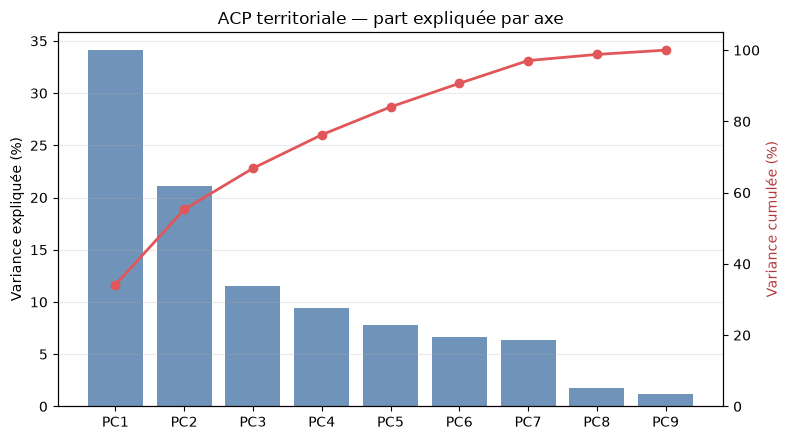

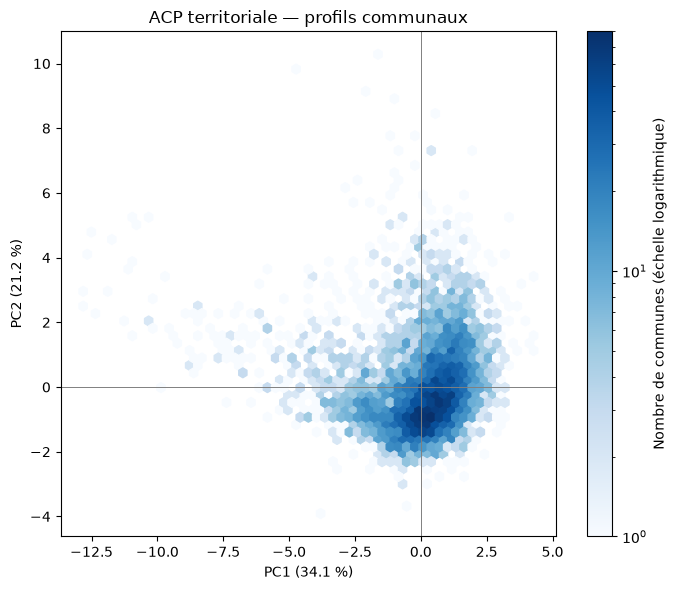

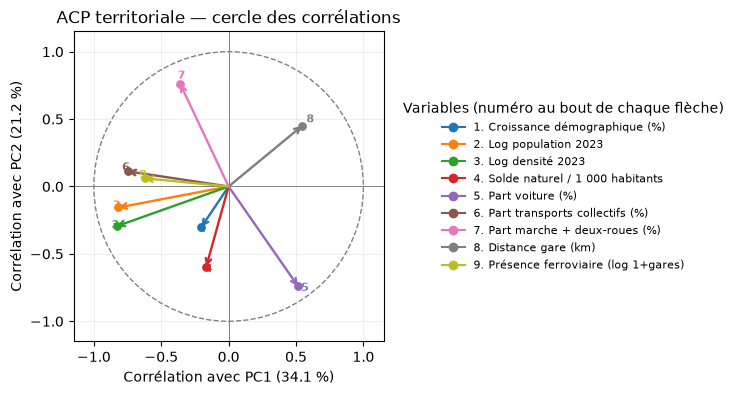

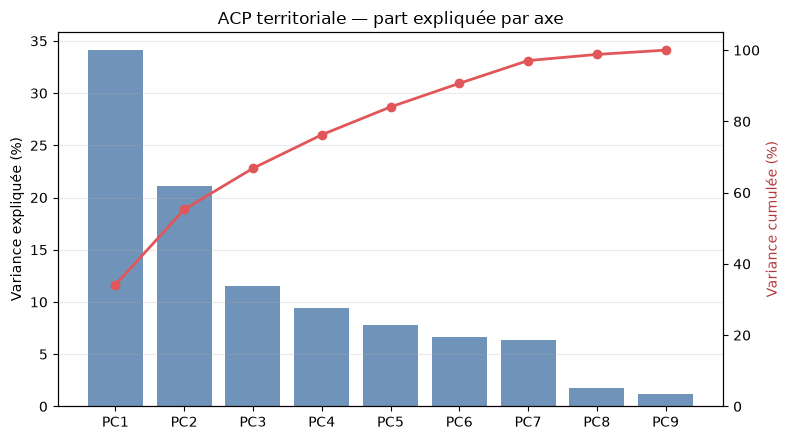

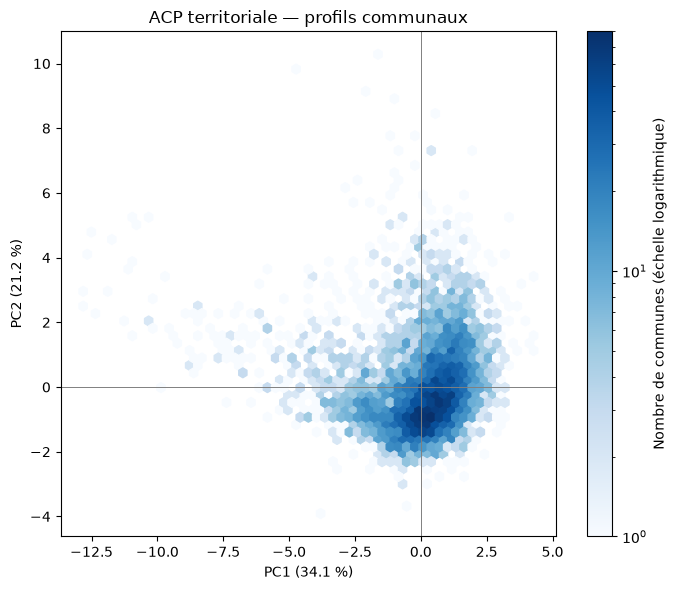

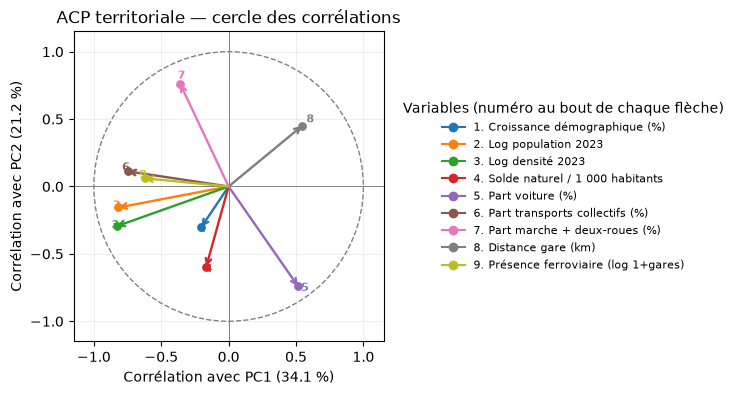

In [14]:
# Préparer les indicateurs qui décrivent la démographie, les déplacements et l'accès au rail.
acp = d.copy()
acp["densite_2023"] = acp["pop_2023"] / acp["superficie_km2"].replace(0, np.nan)
acp["croissance_pop_6ans_pct"] = (
    100 * (acp["pop_2023"] / acp["pop_2017"].replace(0, np.nan) - 1)
)
acp["solde_naturel_pour_1000"] = (
    1000 * (acp["naissances_2017_2022"] - acp["deces_2017_2022"])
    / acp["pop_2017"].replace(0, np.nan)
)
acp["part_voiture_2023"] = (
    100 * acp["actifs_voiture_2023"] / acp["actifs_2023"].replace(0, np.nan)
)
acp["part_transports_2023"] = (
    100 * acp["actifs_transports_commun_2023"] / acp["actifs_2023"].replace(0, np.nan)
)
acp["part_marche_deux_roues_2023"] = (
    100 * (acp["actifs_marche_2023"] + acp["actifs_deux_roues_2023"])
    / acp["actifs_2023"].replace(0, np.nan)
)

# Le logarithme réduit l'effet des communes exceptionnellement grandes ou denses.
X_acp = pd.DataFrame({
    "Croissance démographique (%)": acp["croissance_pop_6ans_pct"],
    "Log population 2023": np.log10(acp["pop_2023"].replace(0, np.nan)),
    "Log densité 2023": np.log10(acp["densite_2023"].replace(0, np.nan)),
    "Solde naturel / 1 000 habitants": acp["solde_naturel_pour_1000"],
    "Part voiture (%)": acp["part_voiture_2023"],
    "Part transports collectifs (%)": acp["part_transports_2023"],
    "Part marche + deux-roues (%)": acp["part_marche_deux_roues_2023"],
    "Distance gare (km)": acp["dist_gare_km"],
    "Présence ferroviaire (log 1+gares)": np.log1p(acp["nb_gares"]),
})

# Le module standardise les variables, calcule les axes et projette les communes.
acp_territoriale = calculer_acp(X_acp)
X_acp = acp_territoriale["donnees"]
table_axes = acp_territoriale["resume_axes"]
scores = acp_territoriale["scores"]
corr_variables = acp_territoriale["correlations"]
contributions = acp_territoriale["contributions"]
print(f"Communes retenues : {len(X_acp):,} sur {len(acp):,}")
display(arrondir_tableau(table_axes))
display(arrondir_tableau(corr_variables.sort_values("PC1", ascending=False)))

# Les 5 communes à chaque extrémité aident à donner un sens concret à chaque axe.
communes_acp = acp.loc[X_acp.index, [
    "code_commune", "nom_commune", "code_region", "pop_2023",
    "densite_2023", "part_voiture_2023", "dist_gare_km",
]]
for axe in ["PC1", "PC2", "PC3"]:
    indices = pd.concat([scores[axe].nlargest(5), scores[axe].nsmallest(5)])
    extremes = communes_acp.loc[indices.index].copy()
    extremes["score"] = indices
    extremes["contribution (%)"] = contributions.loc[indices.index, axe]
    print(f"Communes extrêmes — {axe}")
    display(arrondir_tableau(extremes.sort_values("score", ascending=False)))

# L'hexbin montre où les communes se concentrent ; la légende numérotée clarifie les flèches.
figures_acp = tracer_acp(acp_territoriale, "ACP territoriale")
for figure in figures_acp:
    display(figure)


### Ce que montre l'ACP territoriale

Les deux premiers axes résument **55,28 %** des différences entre les 34 377 communes retenues. PC1 en résume 34,12 % : les communes plus denses, peuplées et bien desservies se trouvent d'un côté, tandis que les communes plus éloignées et plus dépendantes de la voiture se trouvent de l'autre. Les corrélations les plus fortes sont la densité (-0,832), la population (-0,817), la distance à une gare (+0,546) et la part voiture (+0,515).

PC2 ajoute une autre opposition, moins liée à la taille : la marche et les deux-roues (+0,763) s'opposent surtout à la voiture (-0,740). Le solde naturel (-0,595) et la croissance démographique (-0,301) contribuent aussi à cet axe.

On peut donc lire PC1 comme une opposition entre **territoires urbains et bien desservis** et **territoires éloignés où la voiture domine**. PC2 distingue davantage les modes de déplacement. C'est une façon de résumer les différences observées, pas une preuve que le rail provoque la densité.

Communes retenues : 2,435


,Axe,Valeur propre,Variance expliquée (%),Variance cumulée (%)
0,PC1,3.94,43.76,43.76
1,PC2,1.07,11.87,55.63
2,PC3,1.00,11.09,66.73
3,PC4,0.98,10.93,77.66
4,PC5,0.85,9.47,87.13
5,PC6,0.63,7.01,94.14
6,PC7,0.29,3.20,97.35
7,PC8,0.15,1.65,98.99
8,PC9,0.09,1.01,100


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
Part voiture (%),0.87,-0.12,0.02,-0.14,-0.11,-0.35,-0.07,-0.26,-0.10
Distance gare (km),0.18,0.82,0.13,-0.48,0.19,0.08,0.07,-0.06,0.04
Croissance voyageurs (%),0.09,-0.04,0.96,0.22,0.11,-0.01,-0.02,0.00,-0.00
Croissance population (%),-0.20,-0.46,0.21,-0.78,-0.26,0.16,-0.01,0.03,0.01
Nombre de gares,-0.40,0.33,0.10,0.17,-0.83,-0.03,-0.00,-0.02,0.02
Log population 2023,-0.84,0.12,0.05,-0.16,0.07,-0.43,0.12,0.12,-0.17
Part transports collectifs (%),-0.85,-0.03,0.00,0.11,0.08,0.45,0.09,-0.19,-0.14
Log voyageurs 2023,-0.86,0.10,-0.01,-0.07,0.12,-0.08,-0.46,-0.05,0.02
Log densité 2023,-0.88,-0.18,0.01,0.01,0.11,-0.29,0.20,-0.16,0.17


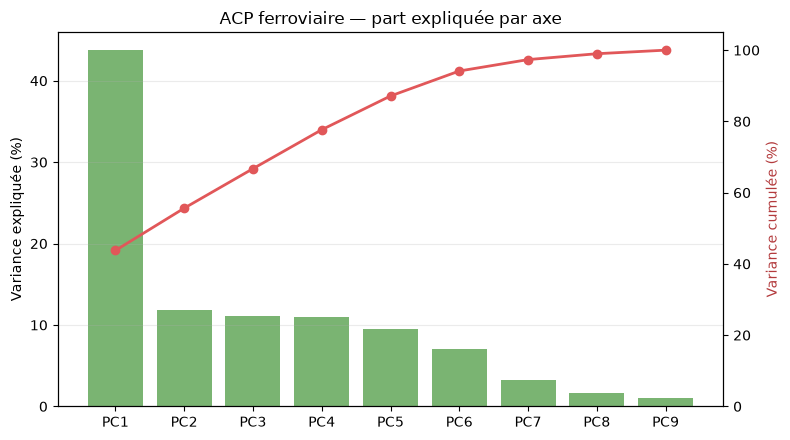

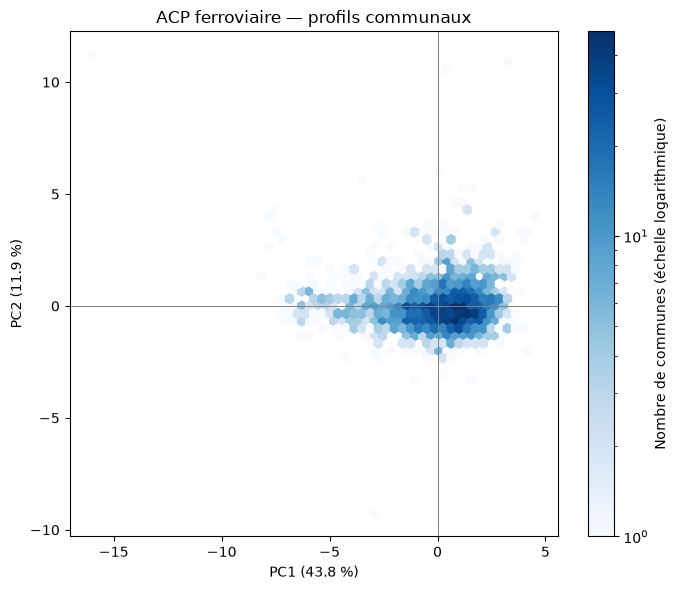

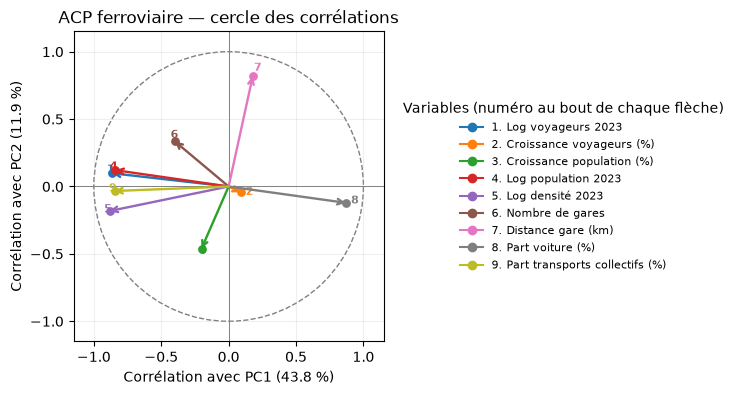

Communes extrêmes — PC1


,nom_commune,code_region,pop_2023,nb_gares,voyageurs_2017,voyageurs_2023,dist_gare_km,score
10603,Locquignol,32,301,1,5,184,5.06,4.55
12037,Aubin-Saint-Vaast,32,733,1,3,1416,0.96,4.22
28773,Porta,76,94,1,2938,5415,3.76,4.12
28176,Les Salelles,76,167,1,2,32,0.52,4.04
28869,Thuès-Entre-Valls,76,25,1,1931,3921,2.21,3.98
34021,Marseille,93,886040,10,15125577,18172887,1.26,-7.50
26859,Toulouse,76,514819,10,11857861,16238761,1.17,-7.62
32746,Lyon,84,519127,6,44201880,52498345,1.10,-7.96
1027,Saint-Denis,11,149077,4,67934497,61196063,1.05,-8.14
0,Paris,11,2103778,26,822301425,757758207,0.40,-16.02


Communes extrêmes — PC2


,nom_commune,code_region,pop_2023,nb_gares,voyageurs_2017,voyageurs_2023,dist_gare_km,score
0,Paris,11,2103778,26,822301425,757758207,0.40,11.24
34045,Les Baux-de-Provence,93,264,1,7963,8091,13.25,11.05
33991,Arles,93,51811,1,715084,810100,13.98,10.39
23042,La Teste-de-Buch,75,27566,1,344846,407005,9.12,5.97
33241,Chamonix-Mont-Blanc,84,8705,10,188147,232642,2.88,5.55
33,Chessy,11,7771,1,6009276,4319252,0.96,-2.50
27632,Saint-Aunès,76,4530,1,2753,10954,0.32,-2.94
26847,Saint-Jory,76,8662,1,155313,274003,1.20,-3.26
16521,Sanry-sur-Nied,44,426,1,9066,9558,1.05,-3.44
14255,Bezannes,44,5039,1,989282,1323545,0.64,-9.27


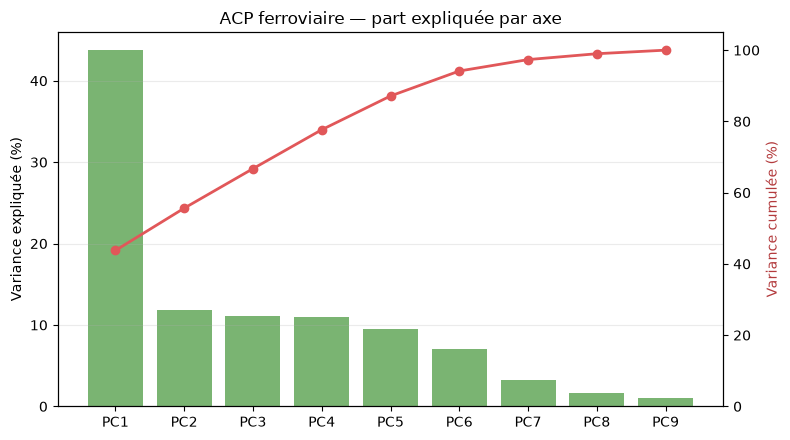

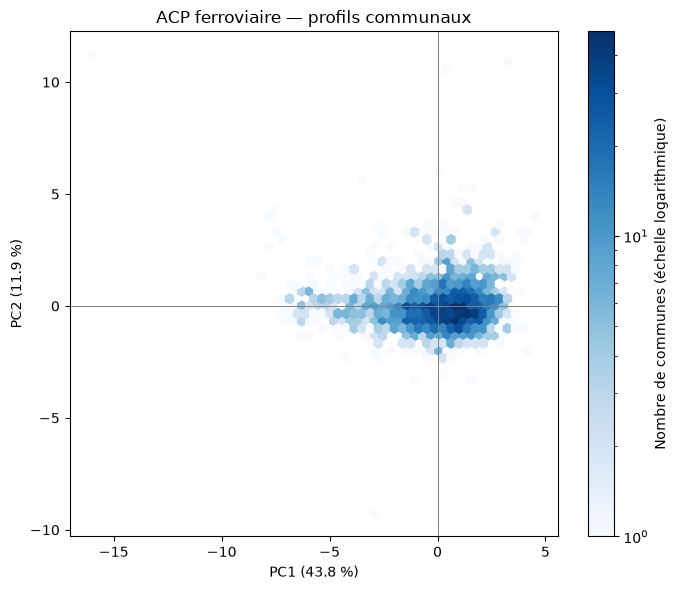

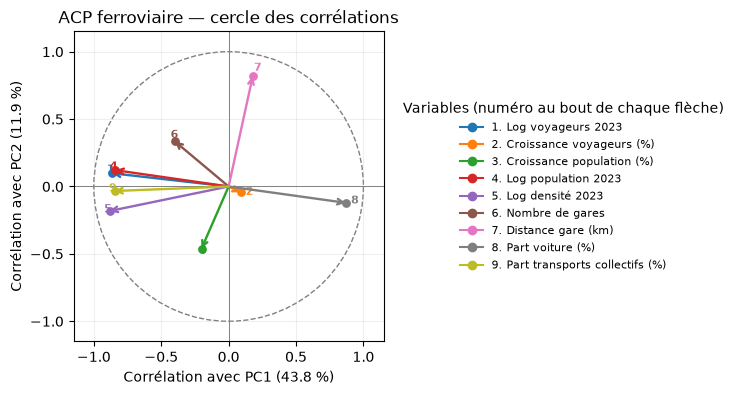

In [15]:
# Garder les communes avec les deux observations de fréquentation et une population 2017 positive.
rail_acp = d[
    d["voyageurs_2017"].notna()
    & d["voyageurs_2023"].notna()
    & d["pop_2017"].gt(0)
].copy()
rail_acp["densite_2023"] = (
    rail_acp["pop_2023"] / rail_acp["superficie_km2"].replace(0, np.nan)
)
rail_acp["croissance_voyageurs_pct"] = (
    100 * (rail_acp["voyageurs_2023"] / rail_acp["voyageurs_2017"].replace(0, np.nan) - 1)
)
rail_acp["croissance_population_pct"] = (
    100 * (rail_acp["pop_2023"] / rail_acp["pop_2017"] - 1)
)
rail_acp["part_voiture_2023"] = (
    100 * rail_acp["actifs_voiture_2023"]
    / rail_acp["actifs_2023"].replace(0, np.nan)
)
rail_acp["part_transport_2023"] = (
    100 * rail_acp["actifs_transports_commun_2023"]
    / rail_acp["actifs_2023"].replace(0, np.nan)
)

# Les volumes sont logarithmés pour qu'une poignée de très grandes villes ne domine pas tout l'axe.
X_rail = pd.DataFrame({
    "Log voyageurs 2023": np.log10(rail_acp["voyageurs_2023"].replace(0, np.nan)),
    "Croissance voyageurs (%)": rail_acp["croissance_voyageurs_pct"],
    "Croissance population (%)": rail_acp["croissance_population_pct"],
    "Log population 2023": np.log10(rail_acp["pop_2023"].replace(0, np.nan)),
    "Log densité 2023": np.log10(rail_acp["densite_2023"].replace(0, np.nan)),
    "Nombre de gares": rail_acp["nb_gares"],
    "Distance gare (km)": rail_acp["dist_gare_km"],
    "Part voiture (%)": rail_acp["part_voiture_2023"],
    "Part transports collectifs (%)": rail_acp["part_transport_2023"],
})

acp_ferroviaire = calculer_acp(X_rail)
X_rail = acp_ferroviaire["donnees"]
scores_rail = acp_ferroviaire["scores"]
corr_rail = acp_ferroviaire["correlations"]
print(f"Communes retenues : {len(X_rail):,}")
display(arrondir_tableau(acp_ferroviaire["resume_axes"]))
display(arrondir_tableau(corr_rail.sort_values("PC1", ascending=False)))

figures_acp_rail = tracer_acp(acp_ferroviaire, "ACP ferroviaire", couleur="#59A14F")
for figure in figures_acp_rail:
    display(figure)

for axe in ["PC1", "PC2"]:
    indices = pd.concat([scores_rail[axe].nlargest(5), scores_rail[axe].nsmallest(5)])
    extremes = rail_acp.loc[indices.index, [
        "nom_commune", "code_region", "pop_2023", "nb_gares",
        "voyageurs_2017", "voyageurs_2023", "dist_gare_km",
    ]].copy()
    extremes["score"] = indices
    print(f"Communes extrêmes — {axe}")
    display(arrondir_tableau(extremes.sort_values("score", ascending=False)))


### Ce que montre l'ACP ferroviaire

Les deux premiers axes résument **55,65 %** des différences entre les 2 435 communes retenues. PC1 explique 43,78 % : le volume de voyageurs, la densité et la population vont ensemble, de même que les transports collectifs. La part voiture se situe à l'autre extrémité de l'axe. PC1 décrit donc surtout l'écart entre grands pôles urbains-ferroviaires et communes plus dépendantes de la voiture.

PC2 est surtout lié à la distance à une gare (+0,816). La croissance du trafic, elle, apparaît principalement sur PC3 : sa corrélation avec cet axe vaut +0,964. Cela montre que le niveau de fréquentation et sa progression sont deux choses distinctes.

Les voyageurs sont regroupés par commune. On ne peut donc pas tirer de conclusion sur chaque gare, ni distinguer les trains régionaux, les RER, les TGV ou les gares touristiques.

### 6.8 Synthèse finale à retenir

L'ACP territoriale montre une structure principale forte : la densité, les transports
collectifs et l'accessibilité ferroviaire sont cohérents, tandis que l'éloignement et
la voiture décrivent l'autre extrémité du territoire.

L'ACP ferroviaire montre que le niveau de fréquentation est surtout lié à la densité,
à la taille communale et aux transports collectifs. La croissance des voyageurs apparaît
comme une troisième dimension distincte, surtout sur PC3.

Ces résultats rendent les deux analyses complémentaires :

- les cartes de population expliquent **qui habite où** ;
- les tableaux modaux expliquent **comment les actifs se déplacent** ;
- l'ACP synthétise **quelles configurations territoriales reviennent ensemble**.